# TZ Fornacis — the literature model, for the paper

The three TZ For figures of the paper, all drawn from **one** model with **nothing fitted**: the published solution of
Gallenne et al. (2016) — $T_{\rm eff}$ 4930 / 6350 K, [Fe/H] +0.02 / −0.05, microturbulence 0.98 / 3.10 km/s,
$v\sin i$ 6.1 / 45.7 km/s, systemic velocities 17.99 / 18.35 km/s, no macroturbulence (their $v\sin i$ come from
broadening functions, which already contain it) — on their light-curve geometry (R 8.34 / 3.97 R$_\odot$, i 85.68°,
Roche surfaces rotating at $v\sin i/\sin i$, so the secondary is flattened), phase-3 emulator, synthesised
**element by element** (exact per-element synthesis) in the literature-model run:

* all HARPS pixels of the 21 epochs, no residual mask, **no** continuum correction (SuppNet-normalised data as they are);
* Clausen (1991) Strömgren b and y phased with the published ephemeris of Andersen et al. (1991), Min I = HJD
  2445032.6091 + 75.66675 E; one zero point per band (differential photometry), no nightly zero points; points
  > 15 mmag from the model dropped (7 of 2338);
* the model dump is `tzfor_aemu_out/tzfor_pure_p3_pure.npz` (Gadi: `/scratch/y89/mj8805/litrepro/interp/out/`,
  job tz-pure in `litrepro/pure/`).

**Ephemeris.** Phase 0 is the deeper minimum (the secondary eclipsed), 0.5 the shallower one. The dump's observed
phases are Andersen's; the spectra use Gallenne's spectroscopic $T_P$.

Figures, in order: how the blended spectrum is built (`tzfor_lit_spectra`), the light curves
(`tzfor_lit_lc`), and the two eclipses zoomed (`tzfor_lit_lc_eclipses`). Colours and sizes live in
`PALETTE` / `STYLE` below; `SAVE` writes png + pdf to `paper_plots/tz_fornacis/`.

## Setup: paths, palette, helpers

In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, Normalize

def _find_scripts(start=Path.cwd()):
    for p in [start, *start.parents, Path("/scratch/y89/mj8805/exactfit/tzfor")]:
        if (p / "tzfor_constants.py").exists():
            return p
    raise FileNotFoundError("tzfor_constants.py not found; set SCRIPTS by hand")

SCRIPTS = _find_scripts()
SEARCH = [p for p in (SCRIPTS / "tzfor_aemu_out", Path("/scratch/y89/mj8805/exactfit/out"), SCRIPTS) if p.is_dir()]
OUT_DIR = SCRIPTS.parent / "paper_plots" / "tz_fornacis"
DUMP = "tzfor_pure_p3_pure.npz"      # Gallenne 2016 unchanged on their light-curve geometry; Andersen 1991 ephemeris; nothing fitted
SAVE = True                         # write png + pdf to OUT_DIR

sys.path.insert(0, str(SCRIPTS))
import tzfor_constants as K

PALETTE = {
    "data": "0.35",          # HARPS spectrum / Stromgren photometry
    "clipped": "0.75",       # photometric points clipped (> 15 mmag from the literature model)
    "model": "C3",           # the SPICE literature model
    "primary": "C0",         # the K giant's contribution
    "secondary": "C1",       # the secondary's contribution
    "residual": "0.4",
}
STYLE = {"ms_point": 3.5, "lw_model": 1.5, "alpha_grid": 0.0, "font_legend": 8.5}
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "savefig.dpi": 150})
C_KMS = 299792.458

def find(name):
    for d in SEARCH:
        if (d / name).exists():
            return d / name
    raise FileNotFoundError(f"{name} not found in {[str(d) for d in SEARCH]}")

def finish(fig, stem):
    if SAVE:
        OUT_DIR.mkdir(parents=True, exist_ok=True)
        for ext in ("png", "pdf"):
            fig.savefig(OUT_DIR / f"{stem}.{ext}", bbox_inches="tight")
        print("saved", OUT_DIR / f"{stem}.pdf")
    plt.show()

d = np.load(find(DUMP), allow_pickle=True)
pn = [str(p) for p in d["pnames"]]; th = np.asarray(d["theta"], float)
P = dict(zip(pn, th))
print(f"{d['synthesis']} model: " + ", ".join(f"{k} {v:.4g}" for k, v in P.items()))
g = d["good"].astype(bool)
print(f"spectra chi2/N {np.mean(((d['obs'] - d['model']) / d['sigma'])[g] ** 2):.3f} on {g.sum():,} pixels")
for b in "by":
    w = d[f"lc_{b}_weight"] > 0; oc = 1000 * (d[f"lc_{b}_obs_mag"] - d[f"lc_{b}_model_at_obs"])[w]
    print(f"Stromgren {b}: rms {np.sqrt(np.mean(oc ** 2)):.2f} mmag on {w.sum()} points ({(~w).sum()} clipped)")

exact per-element model: Teff1 4930, Teff2 6350, feh 0.02, dphi 0
spectra chi2/N 17.481 on 3,016,671 pixels
Stromgren b: rms 3.86 mmag on 1165 points (4 clipped)
Stromgren y: rms 3.56 mmag on 1166 points (3 clipped)


## 1. How the blended spectrum is built

Three phases along the radial-velocity cycle across (giant receding, line systems blended, giant approaching);
the orbit sketch, the giant's contribution, the secondary's contribution, the blend against HARPS and the
residual down. The orbit sketch is solved from the model's own radial velocities, separations to scale, discs
magnified (capped so they never fake a contact). The dotted lines mark `MARK` in each star's frame.

saved /Users/mjablons/code/spice/tutorial/paper_results/paper_plots/tz_fornacis/tzfor_lit_spectra.pdf


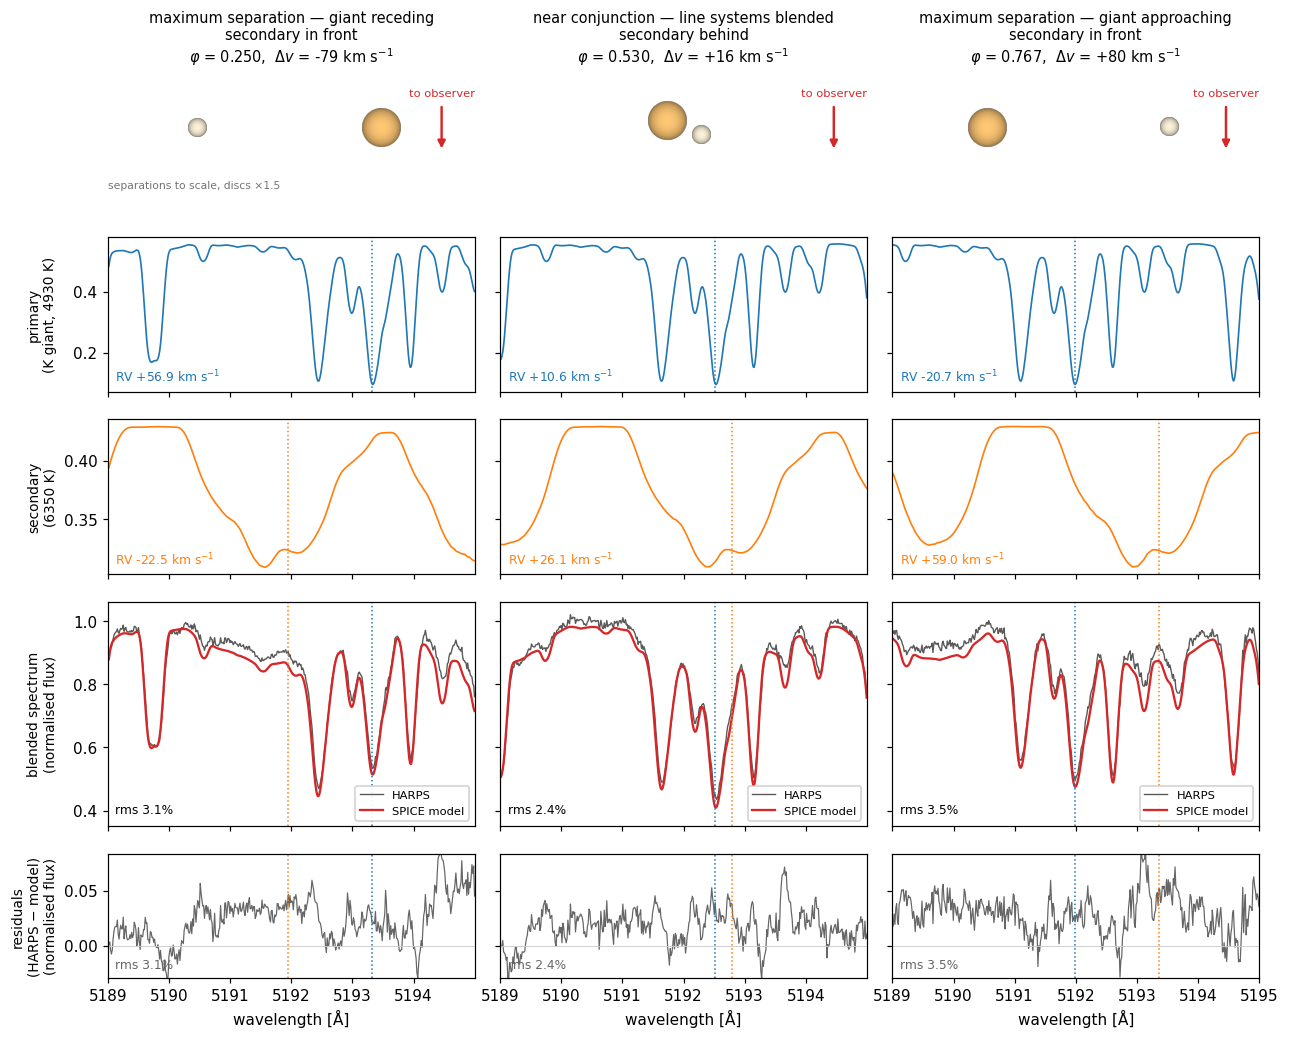

In [2]:
WINDOW = (5189.0, 5195.0)          # Mg b region; any range inside the 5160-5200, 5380-5420, 6100-6140 or 6400-6440 windows
MARK = 5192.34                      # rest wavelength marked in each component's frame (Fe I)
EXAGGERATE = 1.5
STEM = "tzfor_lit_spectra"

STAR_ANCHORS = [(3500, (0.95, 0.55, 0.25)), (4900, (1.00, 0.78, 0.45)), (6300, (1.00, 0.95, 0.85)), (8000, (0.80, 0.87, 1.00))]
def star_colour(teff):
    t = float(np.clip(teff, STAR_ANCHORS[0][0], STAR_ANCHORS[-1][0]))
    for (t0, c0), (t1, c1) in zip(STAR_ANCHORS, STAR_ANCHORS[1:]):
        if t0 <= t <= t1:
            f = (t - t0) / (t1 - t0); return tuple(a + f * (b - a) for a, b in zip(c0, c1))
    return STAR_ANCHORS[-1][1]

def draw_star(ax, x, y, radius, teff, u=0.6, zorder=2):
    gg = np.linspace(-1, 1, 160); X, Y = np.meshgrid(gg, gg); r2 = X ** 2 + Y ** 2
    img = np.where(r2 <= 1, 1 - u * (1 - np.sqrt(np.clip(1 - r2, 0, 1))), np.nan); base = star_colour(teff)
    cmap = LinearSegmentedColormap.from_list("star", [tuple(0.12 * c for c in base), base])
    ax.imshow(img, extent=(x - radius, x + radius, y - radius, y + radius), origin="lower", cmap=cmap,
              norm=Normalize(0.0, 1.0), zorder=zorder, interpolation="bilinear")

T1, T2 = P["Teff1"], P["Teff2"]
R1, R2, incl = P.get("R1", K.PRIMARY_RADIUS), P.get("R2", K.SECONDARY_RADIUS), P.get("incl", K.INCL_DEG)
wl = 10.0 ** d["logwl"]; rv = d["rv"]
phase = ((d["times"] - K.T_P_HJD) % K.PERIOD_DAYS) / K.PERIOD_DAYS
sep = rv[1] - rv[0]

# circular orbit from the radial velocities: RV1 = gamma + K1 cos(2 pi (phase - phase_max))
M = np.column_stack([np.ones_like(phase), np.cos(2 * np.pi * phase), np.sin(2 * np.pi * phase)])
c1 = np.linalg.lstsq(M, rv[0], rcond=None)[0]; K1 = float(np.hypot(c1[1], c1[2]))
ph_max = float(np.arctan2(c1[2], c1[1]) / (2 * np.pi)) % 1.0
theta2 = lambda p_: 2 * np.pi * (p_ - ph_max) + np.pi

EPOCHS = [int(np.argmin(sep)), int(np.argmin(np.abs(sep))), int(np.argmax(sep))]
def title_for(e):
    where = "secondary in front" if np.sin(theta2(phase[e])) > 0 else "secondary behind"
    if abs(sep[e]) < 0.8 * K1:
        return f"near conjunction — line systems blended\n{where}"
    return ("maximum separation — giant receding" if sep[e] < 0 else "maximum separation — giant approaching") + f"\n{where}"

G, Msun, yr, Rsun = 6.67430e-11, 1.98847e30, 3.15576e7, 6.957e8
a = (G * (K.PRIMARY_MASS + K.SECONDARY_MASS) * Msun * (K.PERIOD_YR * yr) ** 2 / (4 * np.pi ** 2)) ** (1 / 3) / Rsun
qm = K.SECONDARY_MASS / K.PRIMARY_MASS
sky_sep = lambda p_: a * np.hypot(np.cos(theta2(p_)), np.cos(np.radians(incl)) * np.sin(theta2(p_)))
EX = min(EXAGGERATE, max(1.0, 0.95 * min(sky_sep(phase[e]) for e in EPOCHS) / (R1 + R2)))

w0, w1 = WINDOW; sel = (wl >= w0) & (wl <= w1)
fig = plt.figure(figsize=(13.5, 11.0))
gs = fig.add_gridspec(5, 3, height_ratios=[1.05, 1.0, 1.0, 1.45, 0.8], hspace=0.17, wspace=0.07)
rows = {"primary": [], "secondary": [], "blend": [], "resid": []}
for col, e in enumerate(EPOCHS):
    last = col == len(EPOCHS) - 1
    ticks = np.arange(np.ceil(w0), np.floor(w1) + 0.1 - (0 if last else 1), 1.0)   # keep the column edges' labels apart
    # orbit sketch
    ax = fig.add_subplot(gs[0, col]); ax.set_aspect("equal"); ax.axis("off")
    th2 = theta2(phase[e]); ci = np.cos(np.radians(incl)); a2, a1 = a / (1 + qm), a * qm / (1 + qm)
    stars = [(-a1 * np.cos(th2), -a1 * ci * np.sin(th2), EX * R1, T1, -np.sin(th2)),
             (a2 * np.cos(th2), a2 * ci * np.sin(th2), EX * R2, T2, np.sin(th2))]
    for x, y, r, t, z in sorted(stars, key=lambda s_: s_[4]):
        draw_star(ax, x, y, r, t, zorder=2 + (z > 0))
    ax.annotate("", xy=(a * 0.82, -a * 0.13), xytext=(a * 0.82, a * 0.13), arrowprops=dict(arrowstyle="-|>", color=PALETTE["model"], lw=1.6))
    ax.text(a * 0.82, a * 0.17, "to observer", color=PALETTE["model"], ha="center", fontsize=7.5)
    ax.set_xlim(-a, a); ax.set_ylim(-a * 0.32, a * 0.32)
    ax.set_title(f"{title_for(e)}\n$\\varphi$ = {phase[e]:.3f},  $\\Delta v$ = {sep[e]:+.0f} km s$^{{-1}}$", fontsize=9.5, pad=4)
    if col == 0:
        ax.text(0.0, -0.02, f"separations to scale, discs ×{EX:g}", transform=ax.transAxes, fontsize=7, color="0.45")
    # the two contributions
    for r, (key, label) in enumerate((("primary", f"primary (K giant, {T1:.0f} K)"), ("secondary", f"secondary ({T2:.0f} K)"))):
        ax = fig.add_subplot(gs[1 + r, col]); rows[key].append(ax); v = rv[r, e]
        ax.plot(wl[sel], d[key][e][sel], color=PALETTE[key], lw=1.1)
        ax.axvline(MARK * (1 + v / C_KMS), color=PALETTE[key], ls=":", lw=1.0)
        ax.set_xlim(w0 + (1e-6 if col else 0), w1); ax.set_xticks(ticks); ax.tick_params(labelbottom=False)
        ax.grid(alpha=STYLE["alpha_grid"]); ax.text(0.02, 0.06, f"RV {v:+.1f} km s$^{{-1}}$", transform=ax.transAxes, fontsize=8, color=PALETTE[key])
        if col == 0: ax.set_ylabel(label.replace(" (", "\n("), fontsize=9)
        else: ax.tick_params(labelleft=False)
    # the blend against HARPS
    obs = np.where(np.isfinite(d["obs"][e]), d["obs"][e], np.nan); mod = d["model"][e]; res = obs - mod
    gd = d["good"][e].astype(bool) & sel; rms = np.sqrt(np.nanmean(res[gd] ** 2))
    ax = fig.add_subplot(gs[3, col]); rows["blend"].append(ax)
    ax.plot(wl[sel], obs[sel], color=PALETTE["data"], lw=0.9, label="HARPS")
    ax.plot(wl[sel], mod[sel], color=PALETTE["model"], lw=STYLE["lw_model"], label="SPICE model")
    ax.set_xlim(w0 + (1e-6 if col else 0), w1); ax.set_xticks(ticks); ax.tick_params(labelbottom=False); ax.set_ylim(0.35, 1.06)
    ax.grid(alpha=STYLE["alpha_grid"]); ax.text(0.02, 0.06, f"rms {100 * rms:.1f}%", transform=ax.transAxes, fontsize=8)
    ax.legend(fontsize=7.5, loc="lower right", framealpha=0.9)
    # the residual
    axr = fig.add_subplot(gs[4, col]); rows["resid"].append(axr)
    axr.plot(wl[sel], res[sel], color=PALETTE["residual"], lw=0.8); axr.axhline(0, color="0.8", lw=0.6)
    axr.set_xlim(w0 + (1e-6 if col else 0), w1); axr.set_xticks(ticks); axr.set_xlabel("wavelength [Å]")
    axr.grid(alpha=STYLE["alpha_grid"]); axr.text(0.02, 0.08, f"rms {100 * rms:.1f}%", transform=axr.transAxes, fontsize=8, color=PALETTE["residual"])
    for v, key in ((rv[0, e], "primary"), (rv[1, e], "secondary")):
        for a_ in (ax, axr):
            a_.axvline(MARK * (1 + v / C_KMS), color=PALETTE[key], ls=":", lw=1.0)
    if col == 0:
        ax.set_ylabel("blended spectrum\n(normalised flux)", fontsize=9); axr.set_ylabel("residuals\n(HARPS − model)\n(normalised flux)", fontsize=9)
    else:
        ax.tick_params(labelleft=False); axr.tick_params(labelleft=False)
for key, axs in rows.items():            # common y limits along each row
    if key == "resid":
        allres = np.concatenate([(d["obs"][e] - d["model"][e])[sel] for e in EPOCHS]); lo, hi = np.nanpercentile(allres, [1, 99]); pad = 0.07 * (hi - lo)
        lo, hi = lo - pad, hi + pad
    else:
        lo = min(a_.get_ylim()[0] for a_ in axs); hi = max(a_.get_ylim()[1] for a_ in axs)
    for a_ in axs: a_.set_ylim(lo, hi)
fig.align_ylabels([axs[0] for axs in rows.values()])
finish(fig, STEM)

## 2. The light curves

Clausen (1991) Strömgren b and y against the literature model over the whole orbit, phase from $T_P$ running
from −0.25 so the deep eclipse (phase 0) is not split. Observed magnitudes are on the model's zero point
(one global zero point per band, no nightly offsets); crosses are the points dropped at > 15 mmag.

saved /Users/mjablons/code/spice/tutorial/paper_results/paper_plots/tz_fornacis/tzfor_lit_lc.pdf


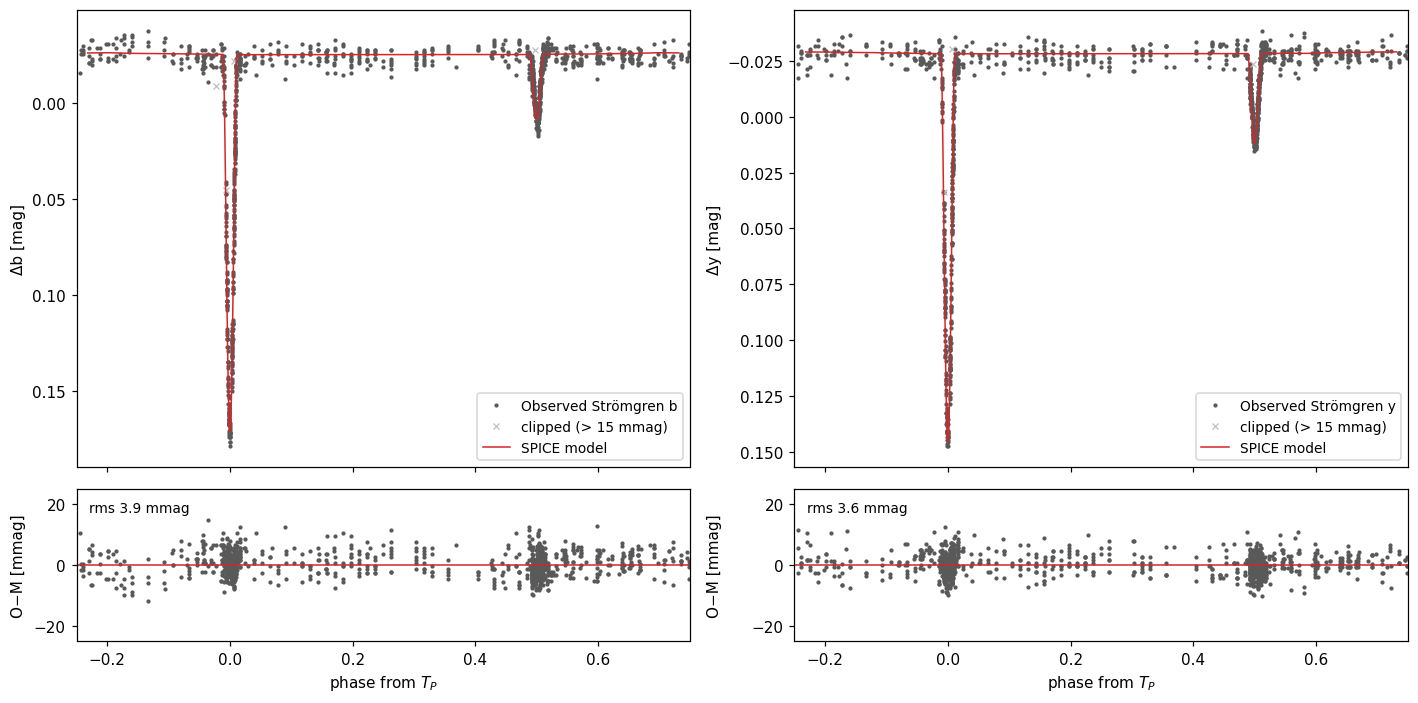

In [3]:
STEM = "tzfor_lit_lc"
wrap = lambda ph: ((np.asarray(ph) + 0.25) % 1.0) - 0.25

fig, axes = plt.subplots(2, 2, figsize=(13, 6.5), gridspec_kw=dict(height_ratios=[3, 1]), sharex="col")
for j, band in enumerate(("b", "y")):
    mp = wrap(d[f"lc_{band}_model_phase"]); o = np.argsort(mp)
    op = wrap(d[f"lc_{band}_obs_phase"]); om = d[f"lc_{band}_obs_mag"]; mo = d[f"lc_{band}_model_at_obs"]; keep = d[f"lc_{band}_weight"] > 0
    ax = axes[0, j]
    ax.plot(op[keep], om[keep], ".", color=PALETTE["data"], ms=STYLE["ms_point"], label=f"Observed Strömgren {band}")
    ax.plot(op[~keep], om[~keep], "x", color=PALETTE["clipped"], ms=4, mew=0.8, label="clipped (> 15 mmag)")
    ax.plot(mp[o], d[f"lc_{band}_model_mag"][o], color=PALETTE["model"], lw=1.0, label="SPICE model")
    ax.invert_yaxis(); ax.set_ylabel(f"Δ{band} [mag]"); ax.grid(alpha=STYLE["alpha_grid"])
    ax.legend(loc="lower right", fontsize=9)
    oc = 1000 * (om - mo); rax = axes[1, j]
    rax.plot(op[keep], oc[keep], ".", color=PALETTE["data"], ms=STYLE["ms_point"]); rax.axhline(0, color=PALETTE["model"], lw=1)
    rax.set_ylim(-25, 25); rax.grid(alpha=STYLE["alpha_grid"])
    rax.text(0.02, 0.85, f"rms {np.sqrt(np.mean(oc[keep] ** 2)):.1f} mmag", transform=rax.transAxes, fontsize=9)
    rax.set_xlabel("phase from $T_P$"); rax.set_ylabel("O−M [mmag]"); rax.set_xlim(-0.25, 0.75)
fig.align_ylabels(); fig.tight_layout(); finish(fig, STEM)

## 3. The eclipses

Both eclipses zoomed, b and y, each with its residual. Magnitudes are relative to the model's out-of-eclipse
level; the rms counts only the points inside each panel.

saved /Users/mjablons/code/spice/tutorial/paper_results/paper_plots/tz_fornacis/tzfor_lit_lc_eclipses.pdf


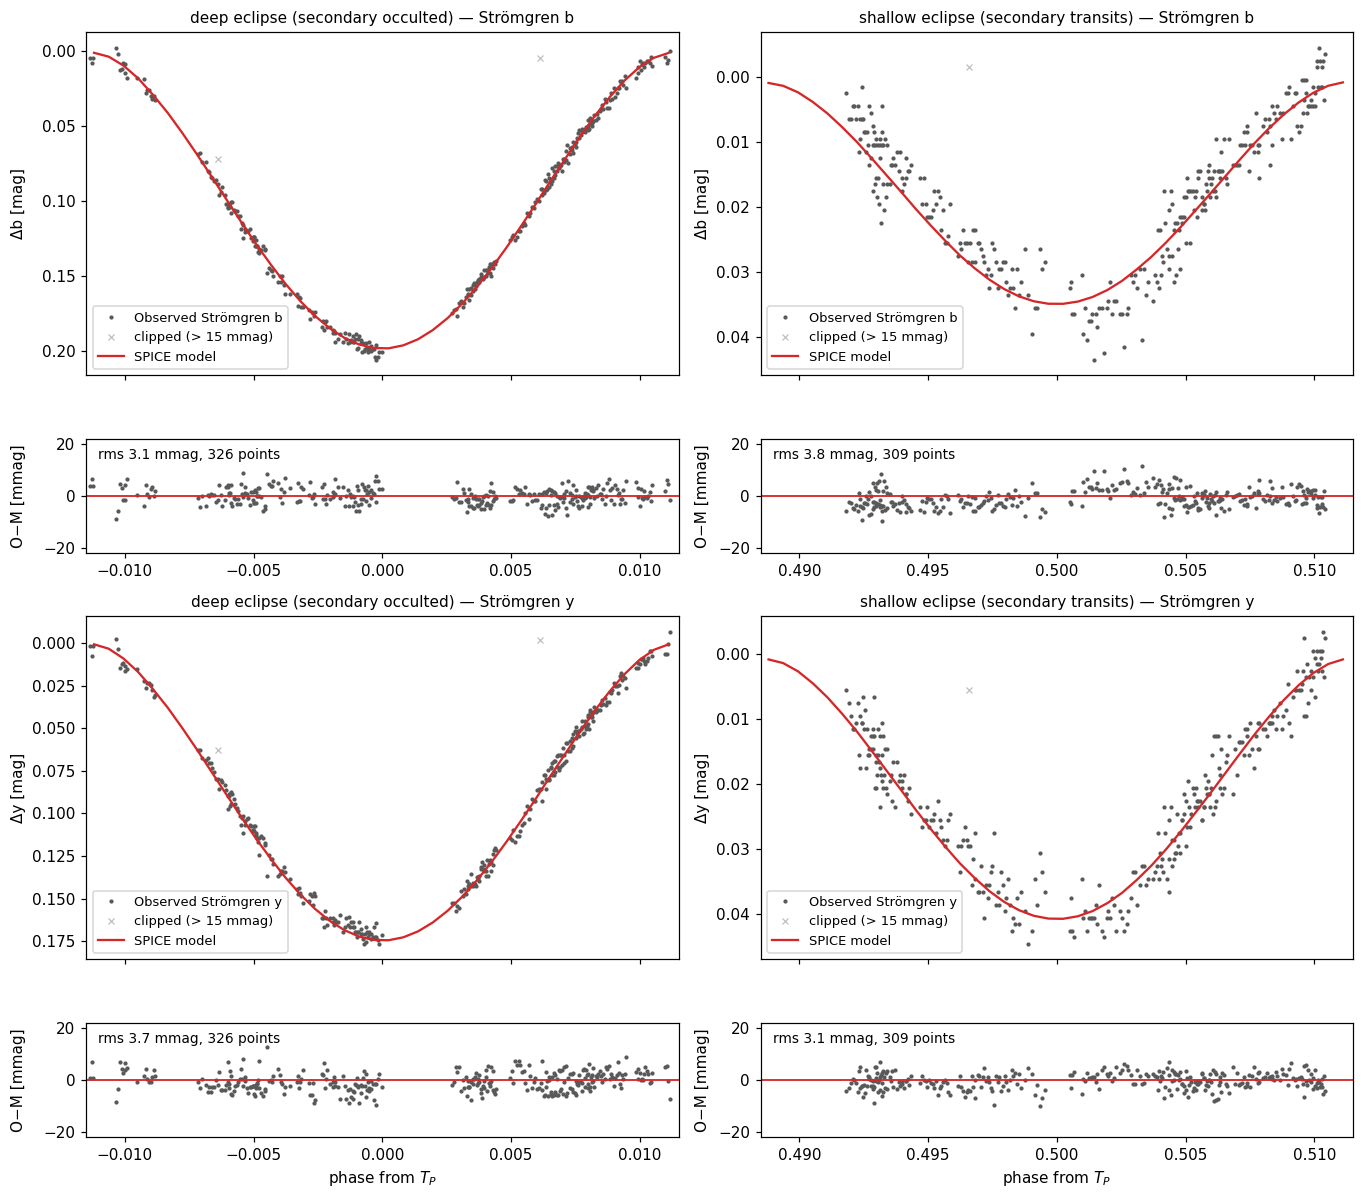

In [4]:
STEM = "tzfor_lit_lc_eclipses"
HALF = 0.0115                       # half-width of each panel in phase
ECLIPSES = [("deep eclipse (secondary occulted)", 0.0), ("shallow eclipse (secondary transits)", 0.5)]
centred = lambda ph, c: ((np.asarray(ph) - c + 0.5) % 1.0) - 0.5 + c       # unwrap around the eclipse centre

fig, axes = plt.subplots(4, 2, figsize=(12.5, 11), gridspec_kw=dict(height_ratios=[3, 1, 3, 1]))
for r, band in enumerate(("b", "y")):
    lev = float(np.min(d[f"lc_{band}_model_mag"]))                         # brightest model point = out of eclipse
    for j, (title, c) in enumerate(ECLIPSES):
        top, bot = axes[2 * r, j], axes[2 * r + 1, j]
        op = centred(d[f"lc_{band}_obs_phase"], c); keep = d[f"lc_{band}_weight"] > 0; s = np.abs(op - c) < HALF
        om = d[f"lc_{band}_obs_mag"] - lev; oc = 1000 * (d[f"lc_{band}_obs_mag"] - d[f"lc_{band}_model_at_obs"])
        mp = centred(d[f"lc_{band}_model_phase"], c); ms = np.abs(mp - c) < HALF + 0.002; o = np.argsort(mp[ms])
        top.plot(op[s & keep], om[s & keep], ".", color=PALETTE["data"], ms=STYLE["ms_point"], label=f"Observed Strömgren {band}")
        if (s & ~keep).any():
            top.plot(op[s & ~keep], om[s & ~keep], "x", color=PALETTE["clipped"], ms=4, mew=0.8, label="clipped (> 15 mmag)")
        top.plot(mp[ms][o], (d[f"lc_{band}_model_mag"] - lev)[ms][o], "-", color=PALETTE["model"], lw=STYLE["lw_model"], label="SPICE model")
        top.invert_yaxis(); top.set_xlim(c - HALF, c + HALF); top.grid(alpha=STYLE["alpha_grid"])
        top.set_title(f"{title} — Strömgren {band}", fontsize=10); top.set_ylabel(f"Δ{band} [mag]")
        top.legend(fontsize=STYLE["font_legend"], loc="lower left"); top.tick_params(labelbottom=False)
        bot.plot(op[s & keep], oc[s & keep], ".", color=PALETTE["data"], ms=STYLE["ms_point"])
        bot.axhline(0, color=PALETTE["model"], lw=1.2); bot.set_ylim(-22, 22); bot.set_xlim(c - HALF, c + HALF); bot.grid(alpha=STYLE["alpha_grid"])
        bot.set_ylabel("O−M [mmag]")
        bot.text(0.02, 0.82, f"rms {np.sqrt(np.mean(oc[s & keep] ** 2)):.1f} mmag, {(s & keep).sum()} points", transform=bot.transAxes, fontsize=9)
        if r == 1: bot.set_xlabel("phase from $T_P$")
fig.align_ylabels(); fig.tight_layout(); finish(fig, STEM)